# ML Assignment 2 - Online Shopper Purchase Prediction

**Problem:** predict whether an e-commerce browsing session ends in a purchase (`Revenue` = True/False)
from 17 session-level features.

**Dataset:** Online Shoppers Purchasing Intention Dataset (UCI Machine Learning Repository, id 468) -
12,330 sessions, 17 features, binary target, about 15% positive class (imbalanced).

Five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) are trained on the
same stratified split and compared on Accuracy, AUC, Precision, Recall, F1 and MCC.
The notebook also saves the models and a test CSV used by the Streamlit app (`app.py`).

Needs `common.py` in the same folder.

## 1. Imports and configuration

In [17]:
import io, json, os, urllib.request, warnings, zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from common import METRIC_COLUMNS, compute_metrics

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- configuration -------------------------------------------------------
DATA_PATH = "online_shoppers_intention.csv"
TARGET = "Revenue"
TEST_SIZE = 0.2
RANDOM_STATE = 42
USE_CLASS_WEIGHT = True      # balance classes for LR / Decision Tree / SVM (KNN and NB have no such option)
MODEL_DIR = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

## 2. Load the dataset


In [18]:

df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
print(f"Dropped {n_dup} duplicate rows -> {df.shape}")
print("Features:", df.shape[1] - 1, "| Rows:", len(df))
assert df.shape[1] - 1 >= 12 and len(df) >= 500, "Assignment needs >= 12 features and >= 500 rows"
df.head()

Raw shape: (12330, 18)
Dropped 125 duplicate rows -> (12205, 18)
Features: 17 | Rows: 12205


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Exploration

In [19]:
print(df.dtypes.to_string())
print("\nMissing values:", int(df.isna().sum().sum()))
df.describe().T

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000


Revenue
False    10297
True      1908
Name: count, dtype: int64
Purchase rate: 15.63%


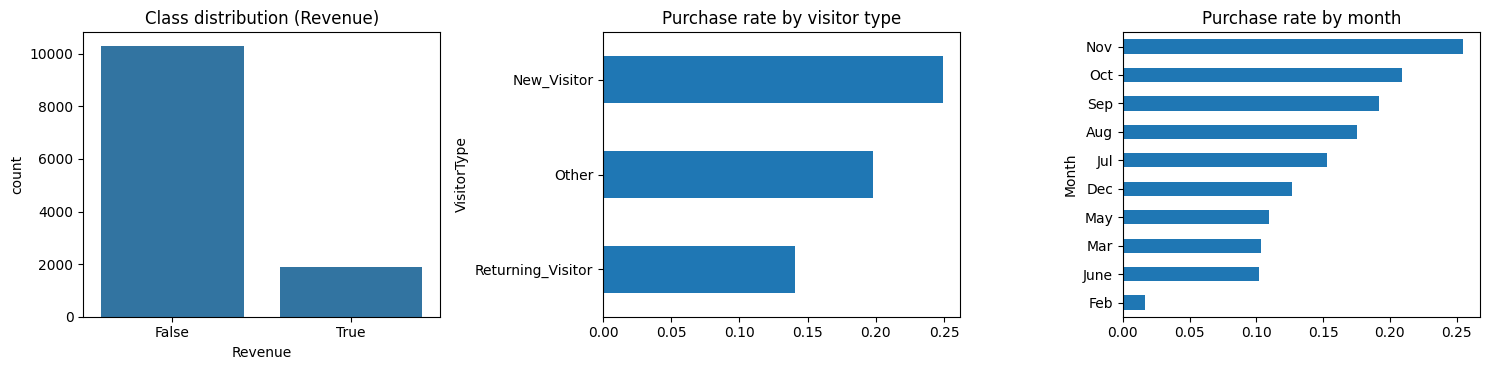

In [20]:
counts = df[TARGET].value_counts()
print(counts)
print(f"Purchase rate: {df[TARGET].mean():.2%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.countplot(x=df[TARGET].astype(str), ax=axes[0])
axes[0].set_title("Class distribution (Revenue)")

rate_vt = df.groupby("VisitorType")[TARGET].mean().sort_values()
rate_vt.plot(kind="barh", ax=axes[1], title="Purchase rate by visitor type")

rate_m = df.groupby("Month")[TARGET].mean().sort_values()
rate_m.plot(kind="barh", ax=axes[2], title="Purchase rate by month")
plt.tight_layout()
plt.show()

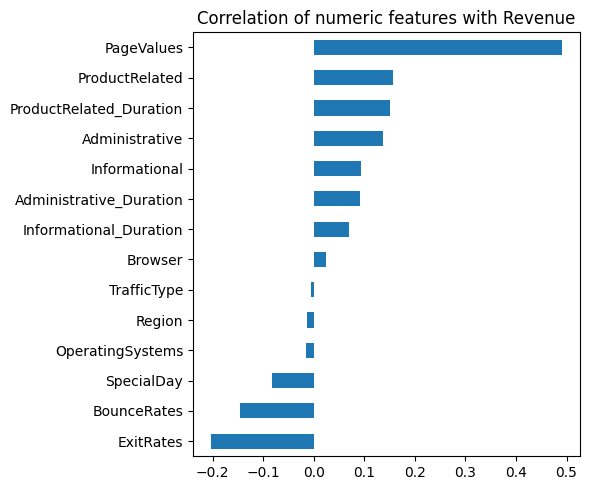

In [21]:
# Which numeric features separate buyers from non-buyers?
num_only = df.select_dtypes(include=[np.number])
corr = num_only.corrwith(df[TARGET].astype(int)).sort_values()
corr.plot(kind="barh", figsize=(6, 5), title="Correlation of numeric features with Revenue")
plt.tight_layout()
plt.show()

## 4. Train/test split and preprocessing

Preprocessing lives inside each saved pipeline (median imputation + scaling for numbers, one-hot for `Month`, `VisitorType`, `Weekend`), so the app can feed raw CSV rows straight to the models. The split is stratified to keep the ~15% purchase rate in both parts.

In [22]:
X = df.drop(columns=[TARGET])
le = LabelEncoder().fit(df[TARGET])          # False -> 0, True -> 1 (positive class = purchase)
y = pd.Series(le.transform(df[TARGET]), name=TARGET)
classes = [str(c) for c in le.classes_]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| Classes:", classes)
print("Positive rate train / test:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))

def build_preprocessor(X):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    print("numeric:", len(num_cols), "| categorical:", cat_cols)
    steps = [("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("sc", StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                      cat_cols))
    return ColumnTransformer(steps)

Train: (9764, 17) | Test: (2441, 17) | Classes: ['False', 'True']
Positive rate train / test: 0.1563 / 0.1565


## 5. Save the test set for the Streamlit app

In [23]:
test_df = X_test.copy()
test_df[TARGET] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)

with open(os.path.join(MODEL_DIR, "meta.json"), "w") as f:
    json.dump({"features": X.columns.tolist(), "target": TARGET, "classes": classes}, f, indent=2)
print("Saved test_data.csv with", len(test_df), "rows")

Saved test_data.csv with 2441 rows


## 6. Train the five models and save them

In [24]:
cw = "balanced" if USE_CLASS_WEIGHT else None

MODELS = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=2000,
            class_weight=cw,
            random_state=RANDOM_STATE
        ),
        "logistic_regression.joblib"
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=10,
            class_weight=cw,
            random_state=RANDOM_STATE
        ),
        "decision_tree.joblib"
    ),
    "KNN": (
        KNeighborsClassifier(n_neighbors=11),
        "knn.joblib"
    ),
    "Naive Bayes": (
        GaussianNB(),
        "naive_bayes.joblib"
    ),
    "Support Vector Machine": (
        SVC(
            kernel="rbf",
            class_weight=cw,
            probability=True,
            random_state=RANDOM_STATE
        ),
        "svm.joblib"
    ),
}

fitted, rows = {}, []

for name, (clf, fname) in MODELS.items():
    pipe = Pipeline([
        ("prep", build_preprocessor(X_train)),
        ("clf", clf)
    ])

    pipe.fit(X_train, y_train)

    joblib.dump(pipe, os.path.join(MODEL_DIR, fname))
    fitted[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)

    rows.append({
        "ML Model Name": name,
        **compute_metrics(y_test, y_pred, y_proba)
    })

    print(f"trained and saved: {name}")

numeric: 14 | categorical: ['Month', 'VisitorType', 'Weekend']
trained and saved: Logistic Regression
numeric: 14 | categorical: ['Month', 'VisitorType', 'Weekend']
trained and saved: Decision Tree
numeric: 14 | categorical: ['Month', 'VisitorType', 'Weekend']
trained and saved: KNN
numeric: 14 | categorical: ['Month', 'VisitorType', 'Weekend']
trained and saved: Naive Bayes
numeric: 14 | categorical: ['Month', 'VisitorType', 'Weekend']
trained and saved: Support Vector Machine


## 7. Comparison table

In [25]:
results = pd.DataFrame(rows)
results.to_csv(os.path.join(MODEL_DIR, "metrics.csv"), index=False)
results.round(4).style.format({c: "{:.4f}" for c in METRIC_COLUMNS}).highlight_max(subset=METRIC_COLUMNS, color="#cfe8cf")

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8513,0.9109,0.5164,0.7853,0.6231,0.5536
1,Decision Tree,0.8439,0.9220,0.5008,0.8246,0.6231,0.5583
2,KNN,0.8791,0.8355,0.7231,0.3691,0.4887,0.4595
3,Naive Bayes,0.7108,0.8263,0.3288,0.8141,0.4684,0.3772
4,Support Vector Machine,0.8681,0.9064,0.5573,0.7644,0.6446,0.5767


In [26]:

print(results.round(4).to_markdown(index=False))

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.8513 | 0.9109 |      0.5164 |   0.7853 | 0.6231 | 0.5536 |
| Decision Tree          |     0.8439 | 0.922  |      0.5008 |   0.8246 | 0.6231 | 0.5583 |
| KNN                    |     0.8791 | 0.8355 |      0.7231 |   0.3691 | 0.4887 | 0.4595 |
| Naive Bayes            |     0.7108 | 0.8263 |      0.3288 |   0.8141 | 0.4684 | 0.3772 |
| Support Vector Machine |     0.8681 | 0.9064 |      0.5573 |   0.7644 | 0.6446 | 0.5767 |


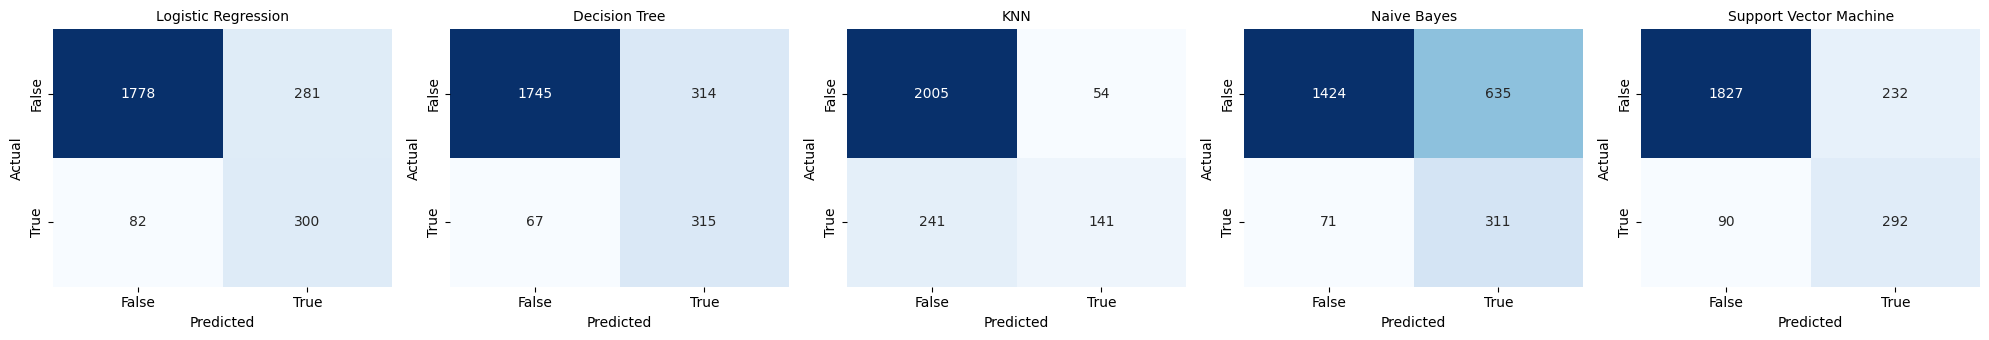

In [27]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 3.5))
for ax, (name, pipe) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 9. ROC curves and metric comparison

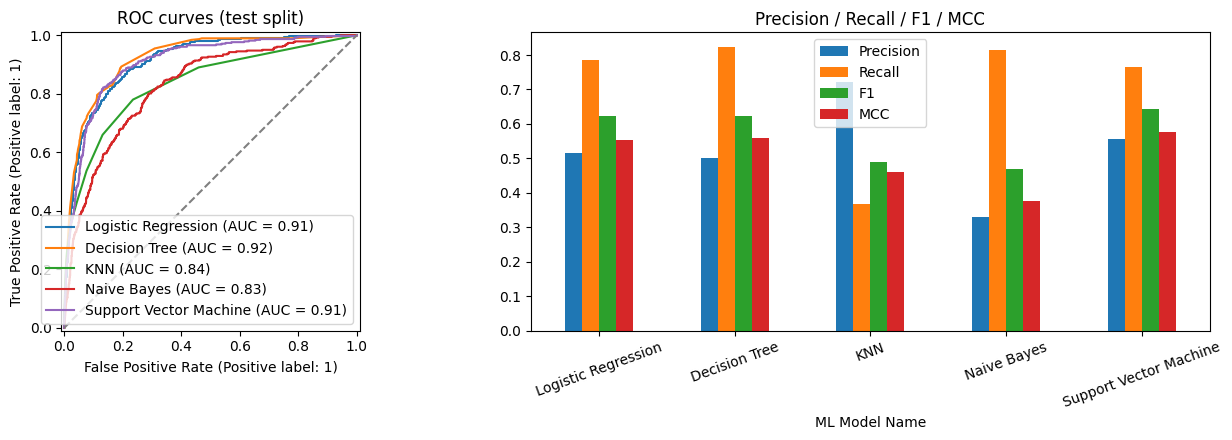

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_title("ROC curves (test split)")

results.set_index("ML Model Name")[["Precision", "Recall", "F1", "MCC"]].plot(kind="bar", ax=axes[1], rot=20)
axes[1].set_title("Precision / Recall / F1 / MCC")
plt.tight_layout()
plt.show()

## 10. Winner

In [33]:
best = results.sort_values(["MCC", "AUC"], ascending=False).iloc[0]
print("Highest MCC (ties broken by AUC):", best["ML Model Name"])

Highest MCC (ties broken by AUC): Support Vector Machine
